# Presentación: el dataset UNSW-NB15

Resumen del análisis exploratorio (`01_exploration.ipynb`): cómo es el dataset, cómo se distribuye y qué decidimos para preparar los datos. El código sale del notebook principal.

Todas las decisiones se tomaron con el entrenamiento; la prueba solo la usamos para comparar.

## 1. Configuración y carga

Cargamos las librerías y buscamos la carpeta del proyecto, para no depender de rutas fijas.

In [57]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

# Raíz del proyecto: la primera carpeta hacia arriba que contiene pyproject.toml.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RAW_DIR = ROOT / "data" / "raw"

ID_COL = "id"
TARGET = "label"
ATTACK_CAT = "attack_cat"

Usamos la partición oficial de UNSW-NB15: entrenamiento, prueba y la descripción de las variables.

In [58]:
train = pd.read_csv(RAW_DIR / "UNSW_NB15_training-set.csv")
test = pd.read_csv(RAW_DIR / "UNSW_NB15_testing-set.csv")
features = pd.read_csv(RAW_DIR / "NUSW-NB15_features.csv", encoding="cp1252")

print(f"Entrenamiento: {train.shape[0]:,} flujos x {train.shape[1]} columnas")
print(f"Prueba:        {test.shape[0]:,} flujos x {test.shape[1]} columnas")
print(f"Descripción:   {features.shape[0]} variables")

Entrenamiento: 175,341 flujos x 45 columnas
Prueba:        82,332 flujos x 45 columnas
Descripción:   49 variables


Antes de explorar revisamos la **calidad de los datos**, en entrenamiento y en prueba: celdas vacías, valores que esconden un dato faltante (textos vacíos o `-`), valores imposibles (negativos o infinitos, porque las variables son conteos, tamaños, tiempos y tasas) y columnas que no aportan porque siempre valen lo mismo:

In [59]:
def quality_checks(df):
    """Cuenta los problemas de calidad más comunes en un conjunto de flujos."""
    text = df.select_dtypes(include="str")
    numbers = df.select_dtypes(include="number").drop(columns=ID_COL)
    return pd.Series({
        "celdas vacías (NaN)": int(df.isna().sum().sum()),
        "textos vacíos o solo espacios": int(text.apply(lambda s: s.str.strip().eq("")).sum().sum()),
        "valores '-' en las categóricas": int(text.eq("-").sum().sum()),
        "valores negativos": int((numbers < 0).sum().sum()),
        "valores infinitos": int(np.isinf(numbers).sum().sum()),
        "columnas con un solo valor": int((df.nunique() == 1).sum()),
    })


dash_share = train.select_dtypes(include="str").eq("-").mean()
print(f"Columnas con '-': {', '.join(f'{c} ({p:.1%} de los flujos)' for c, p in dash_share[dash_share > 0].items())}")
pd.DataFrame({"entrenamiento": quality_checks(train), "prueba": quality_checks(test)})

Columnas con '-': service (53.7% de los flujos)


,entrenamiento,prueba
celdas vacías (NaN),0,0
textos vacíos o solo espacios,0,0
valores '-' en las categóricas,94168,47153
valores negativos,0,0
valores infinitos,0,0
columnas con un solo valor,0,0


- **No hay celdas vacías, negativos ni infinitos**, y ninguna columna es constante: no hay que rellenar ni corregir nada.
- **El único dato "faltante" es el `-` de `service`**, en más de la mitad de los flujos. Según la descripción oficial significa "servicio poco usado", no un error, y dice algo: con `-` hay 61 % de ataques y con servicio identificado, 76 %.

> **Decisión 1:** el `-` de `service` se trata como una categoría más, igual que `http` o `dns`.
>
> **Decisión 16:** como la app puede recibir CSV con problemas que estos datos no tienen, un flujo con un valor numérico vacío, no numérico o negativo se rechaza con un mensaje claro, sin inventar el valor.

## 2. ¿Cómo es el dataset?

Cada fila es un **flujo**: una conexión de red resumida en números (duración, bytes, paquetes, TTL...). Al final van las etiquetas: `label` (0 = normal, 1 = ataque) y `attack_cat` (tipo de ataque).

In [60]:
train.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,252,254,14158.942380,8495.365234,0,0,24.295600,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,62,252,8395.112305,503571.312500,2,17,49.915000,15.432865,61.426934,1387.778330,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,62,252,1572.271851,60929.230470,1,6,231.875571,102.737203,17179.586860,11420.926230,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,62,252,2740.178955,3358.622070,1,3,152.876547,90.235726,259.080172,4991.784669,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,254,252,8561.499023,3987.059814,2,1,47.750333,75.659602,2415.837634,115.807000,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0


Tenemos 3 variables categóricas y 39 numéricas. Las particiones no traen IPs, puertos ni tiempos. `id` es solo el número de fila: no se usa como variable, porque el modelo solo podría memorizarlo.

In [61]:
categorical_cols = [c for c in train.select_dtypes(include="str").columns if c != ATTACK_CAT]
numeric_cols = [c for c in train.select_dtypes(include="number").columns if c not in (ID_COL, TARGET)]

print(f"Categóricas ({len(categorical_cols)}): {categorical_cols}")
print(f"Numéricas ({len(numeric_cols)}): {numeric_cols}")

Categóricas (3): ['proto', 'service', 'state']
Numéricas (39): ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']


## 3. Flujos repetidos

Sin IPs ni tiempos, conexiones distintas pueden quedar idénticas. Agrupamos las filas iguales en patrones:

In [62]:
feature_cols = categorical_cols + numeric_cols
print(f"Variables de entrada: {len(feature_cols)}")


def flow_pattern_ids(df, columns):
    """Devuelve un id por fila; las filas con los mismos valores en `columns` comparten el id."""
    return pd.util.hash_pandas_object(df[columns], index=False)


pattern_id = flow_pattern_ids(train, feature_cols)
group_size = pattern_id.map(pattern_id.value_counts())

print(f"Flujos:                        {len(train):,}")
print(f"Patrones distintos:            {pattern_id.nunique():,}")
print(f"Flujos que repiten un patrón:  {pattern_id.duplicated().sum():,} ({pattern_id.duplicated().mean():.1%})")
print(f"Flujos con un patrón único:    {(group_size == 1).sum():,} ({(group_size == 1).mean():.1%})")
print(f"Grupo más grande:              {group_size.max():,} flujos")

Variables de entrada: 42
Flujos:                        175,341
Patrones distintos:            101,040
Flujos que repiten un patrón:  74,301 (42.4%)
Flujos con un patrón único:    91,292 (52.1%)
Grupo más grande:              415 flujos


Los que más se repiten son los ataques automatizados (`Generic`, `DoS`); el tráfico normal casi no se repite:

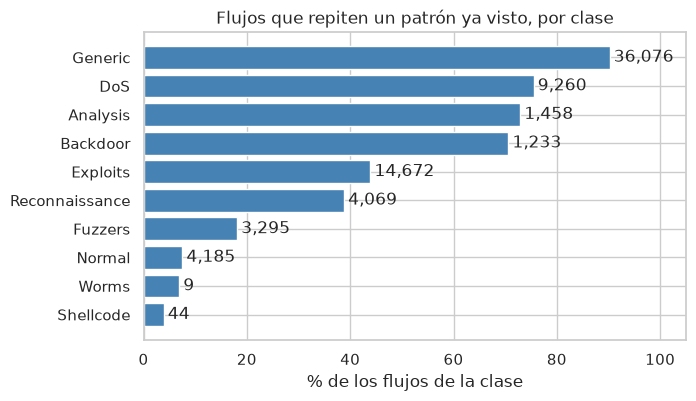

,flows,repeated,repeated_pct
attack_cat,,,
Shellcode,1133,44,3.9
Worms,130,9,6.9
Normal,56000,4185,7.5
Fuzzers,18184,3295,18.1
Reconnaissance,10491,4069,38.8
Exploits,33393,14672,43.9
Backdoor,1746,1233,70.6
Analysis,2000,1458,72.9
DoS,12264,9260,75.5


In [63]:
repeated = pattern_id.duplicated()
repeated_by_class = pd.DataFrame({
    "flows": train[ATTACK_CAT].value_counts(),
    "repeated": train.loc[repeated, ATTACK_CAT].value_counts(),
}).fillna(0).astype(int)
repeated_by_class["repeated_pct"] = (repeated_by_class["repeated"] / repeated_by_class["flows"] * 100).round(1)
repeated_by_class = repeated_by_class.sort_values("repeated_pct")

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(repeated_by_class.index, repeated_by_class["repeated_pct"], color="steelblue")
ax.bar_label(bars, labels=[f"{n:,}" for n in repeated_by_class["repeated"]], padding=3)
ax.set_title("Flujos que repiten un patrón ya visto, por clase")
ax.set_xlabel("% de los flujos de la clase")
ax.set_xlim(0, 105)
plt.show()

repeated_by_class

> **Decisión 2:** no eliminamos los repetidos, porque son conexiones distintas y su frecuencia es información real. En la validación, cada grupo de flujos idénticos va completo a entrenamiento o a validación, para no evaluar con flujos ya vistos.

## 4. Distribución de las clases

Flujos, porcentaje, desbalance y patrones distintos por clase, primero en la tarea binaria y luego por tipo de ataque:

In [64]:
def class_distribution(target):
    """Flujos, porcentaje, razón de desbalance y patrones distintos por clase de `target`."""
    counts = train[target].value_counts()
    return pd.DataFrame({
        "flujos": counts,
        "%": (counts / len(train) * 100).round(2),
        "razón frente a la mayor": (counts.max() / counts).round(1),
        "patrones distintos": pattern_id.groupby(train[target]).nunique(),
    }).sort_values("flujos", ascending=False)


label_distribution = class_distribution(TARGET).rename(index={0: "0 · normal", 1: "1 · ataque"})
label_distribution

,flujos,%,razón frente a la mayor,patrones distintos
label,,,,
1 · ataque,119341,68.06,1.0,49379
0 · normal,56000,31.94,2.1,51890


Por tipo de ataque:

In [65]:
attack_cat_distribution = class_distribution(ATTACK_CAT)
attack_cat_distribution

,flujos,%,razón frente a la mayor,patrones distintos
attack_cat,,,,
Normal,56000,31.94,1.0,51890
Generic,40000,22.81,1.4,4181
Exploits,33393,19.04,1.7,19844
Fuzzers,18184,10.37,3.1,16150
DoS,12264,6.99,4.6,3806
Reconnaissance,10491,5.98,5.3,7522
Analysis,2000,1.14,28.0,1594
Backdoor,1746,1.00,32.1,1535
Shellcode,1133,0.65,49.4,1091


En la gráfica de la derecha el eje es logarítmico; si no, `Worms` no se vería.

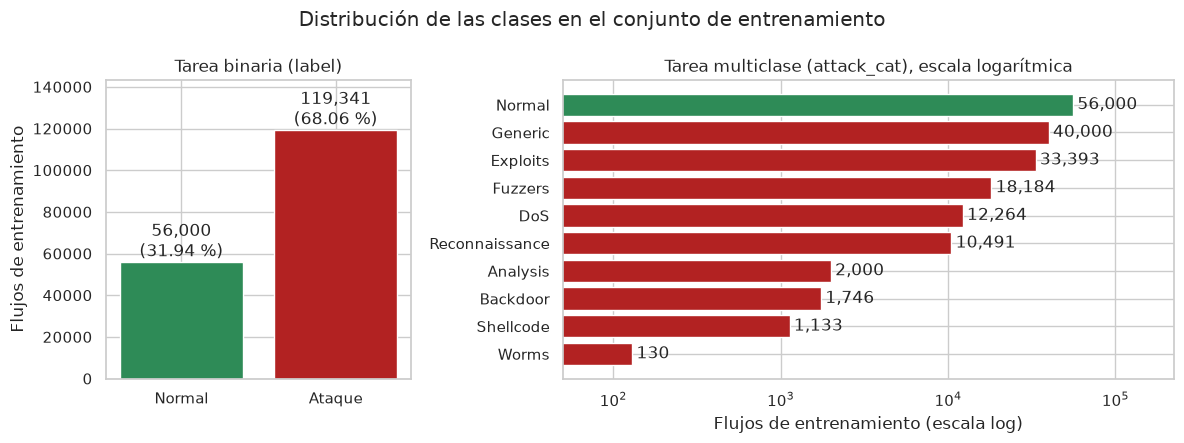

In [66]:
fig, (ax_label, ax_cat) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1, 2]})

binary = label_distribution.loc[["0 · normal", "1 · ataque"]]  # orden fijo: normal, ataque
bars = ax_label.bar(["Normal", "Ataque"], binary["flujos"].to_numpy(), color=["seagreen", "firebrick"])
ax_label.bar_label(bars, labels=[f"{n:,}\n({p} %)" for n, p in zip(binary["flujos"], binary["%"])])
label_counts = binary["flujos"]
ax_label.set_ylim(0, label_counts.max() * 1.2)
ax_label.set_title("Tarea binaria (label)")
ax_label.set_ylabel("Flujos de entrenamiento")

cat_counts = attack_cat_distribution["flujos"].sort_values()
colors = ["seagreen" if c == "Normal" else "firebrick" for c in cat_counts.index]
bars = ax_cat.barh(cat_counts.index, cat_counts.to_numpy(), color=colors)
ax_cat.bar_label(bars, labels=[f"{n:,}" for n in cat_counts], padding=3)
ax_cat.set_xscale("log")
ax_cat.set_xlim(50, cat_counts.max() * 4)
ax_cat.set_title("Tarea multiclase (attack_cat), escala logarítmica")
ax_cat.set_xlabel("Flujos de entrenamiento (escala log)")

fig.suptitle("Distribución de las clases en el conjunto de entrenamiento")
fig.tight_layout()
plt.show()

- **Binaria:** 68 % de ataques, al revés de una red real. En patrones distintos las clases están casi iguales: el desbalance viene de las repeticiones.
- **Por tipo:** `Normal` tiene 431 veces más flujos que `Worms`.
- **La exactitud engaña:** un modelo que diga siempre "ataque" acierta el 68 % sin aprender nada, y uno que ignore los tipos pequeños casi no pierde exactitud. Qué métricas usar lo decidimos en la etapa de entrenamiento.

> **Decisión 5:** la separación por grupos se estratifica por `attack_cat`, para que hasta `Worms` quede en la validación. Cómo compensar el desbalance lo decidimos en la etapa de entrenamiento.

## 5. Variables numéricas

Las variables tienen colas muy largas. Arriba, la distribución original; abajo, con `log1p` (log(1 + x)), donde se ven diferencias entre normal y ataque que antes no aparecían:

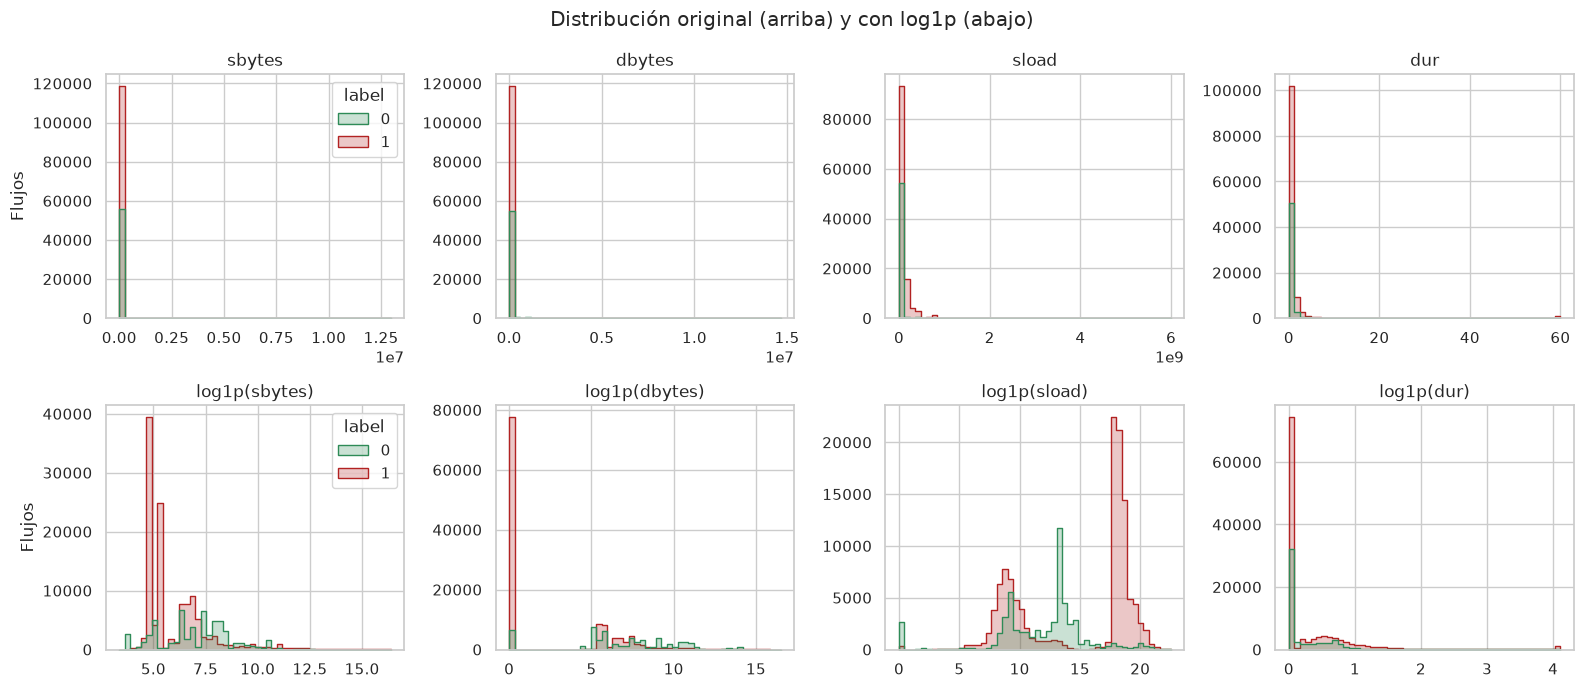

In [67]:
examples = ["sbytes", "dbytes", "sload", "dur"]
palette = {0: "seagreen", 1: "firebrick"}

fig, axes = plt.subplots(2, len(examples), figsize=(16, 7))
for i, col in enumerate(examples):
    for row, (values, title) in enumerate([(train[col], col), (np.log1p(train[col]), f"log1p({col})")]):
        ax = axes[row, i]
        sns.histplot(x=values, hue=train[TARGET], bins=50, palette=palette, element="step", ax=ax, legend=(i == 0))
        ax.set_title(title)
        ax.set_xlabel("")
        ax.set_ylabel("Flujos" if i == 0 else "")
axes[0, 0].get_legend().set_title("label")
fig.suptitle("Distribución original (arriba) y con log1p (abajo)")
fig.tight_layout()
plt.show()

> **Decisión 7:** aplicamos siempre `log1p` a 21 variables continuas asimétricas. No cambia el orden de los valores, así que no afecta a los árboles y ayuda a los demás modelos.

Las colas largas también dejan muchos valores atípicos. ¿Son errores que hay que quitar o información? Marcamos como atípico lo que queda a más de 1,5 × IQR de la caja y miramos cuántos de esos flujos son ataques:

In [ ]:
# Regla IQR: atípico = por debajo de Q1 − 1,5·IQR o por encima de Q3 + 1,5·IQR.
q1 = train[numeric_cols].quantile(0.25)
q3 = train[numeric_cols].quantile(0.75)
iqr = q3 - q1
is_outlier = (train[numeric_cols] < q1 - 1.5 * iqr) | (train[numeric_cols] > q3 + 1.5 * iqr)

outlier_summary = pd.DataFrame({
    "% atípicos": (is_outlier.mean() * 100).round(1),
    "% ataques entre los atípicos": [
        round(train.loc[is_outlier[c], TARGET].mean() * 100, 1) if is_outlier[c].any() else np.nan
        for c in numeric_cols
    ],
}).sort_values("% atípicos", ascending=False)

print(f"Proporción general de ataques: {train[TARGET].mean():.1%}")
print(f"Flujos con al menos un valor atípico en alguna variable: {is_outlier.any(axis=1).mean():.1%}")
outlier_summary.head(15)

- **El 81 % de los flujos tiene algún atípico:** con colas tan largas, la regla marca casi toda la cola. Quitarlos dejaría menos de una quinta parte de los datos.
- **Son información, no errores:** en los conteos `ct_*`, entre el 95 % y el 100 % de los atípicos son ataques (muchas conexiones seguidas, como en un escaneo); en `dload`, solo el 11 % (descargas grandes normales).

> **Decisión 6:** no quitamos ni recortamos los valores atípicos. En la app, un valor mayor que los vistos en entrenamiento se procesa normalmente.

## 6. Variables categóricas

`proto` tiene 133 categorías, casi todas con muy pocos flujos:

In [68]:
train_counts = {col: train[col].value_counts() for col in categorical_cols}

pd.DataFrame({
    "categorías en entrenamiento": {c: train[c].nunique() for c in categorical_cols},
    "categorías en prueba": {c: test[c].nunique() for c in categorical_cols},
    "con < 1.000 flujos": {c: int((train_counts[c] < 1000).sum()) for c in categorical_cols},
    "con < 100 flujos": {c: int((train_counts[c] < 100).sum()) for c in categorical_cols},
    "más frecuente": {c: f"{train_counts[c].index[0]} ({train_counts[c].iloc[0] / len(train):.0%})" for c in categorical_cols},
})

,categorías en entrenamiento,categorías en prueba,con < 1.000 flujos,con < 100 flujos,más frecuente
proto,133,131,127,31,tcp (46%)
service,13,13,5,5,- (54%)
state,9,7,5,5,INT (47%)


Juntamos en `other` las categorías con menos de 1.000 flujos. Las que quedan conservan su información (`arp` normal, `other` casi todo ataque; `ssh` frente a `pop3`; `CON` frente a `INT`):

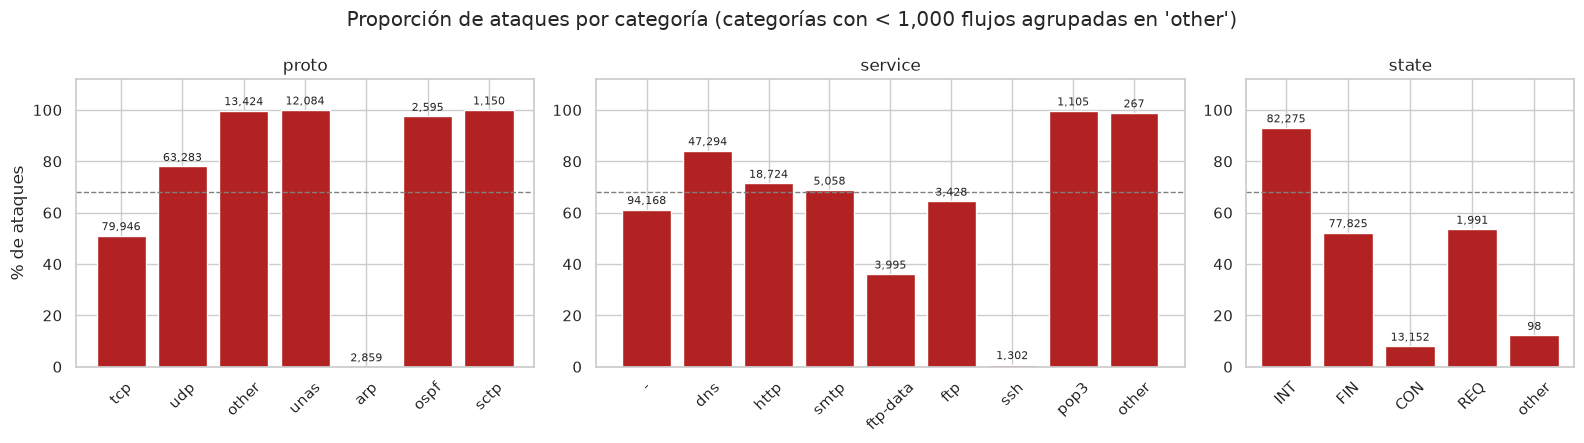

In [69]:
MIN_CATEGORY_COUNT = 1000

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={"width_ratios": [7, 9, 5]})
for ax, col in zip(axes, categorical_cols):
    kept = train_counts[col].index[train_counts[col] >= MIN_CATEGORY_COUNT]
    grouped = train[col].where(train[col].isin(kept), "other")  # solo para visualizar
    rates = (
        train.groupby(grouped)[TARGET].agg(flows="size", attack_rate="mean")
        .sort_values("flows", ascending=False)
    )
    bars = ax.bar(rates.index, rates["attack_rate"] * 100, color="firebrick")
    ax.bar_label(bars, labels=[f"{n:,}" for n in rates["flows"]], fontsize=8, padding=2)
    ax.axhline(train[TARGET].mean() * 100, color="gray", linestyle="--", linewidth=1)
    ax.set_ylim(0, 112)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)
    ax.set_ylabel("% de ataques" if col == categorical_cols[0] else "")
fig.suptitle(f"Proporción de ataques por categoría (categorías con < {MIN_CATEGORY_COUNT:,} flujos agrupadas en 'other')")
fig.tight_layout()
plt.show()

> **Decisión 8:** las categorías con menos de 1.000 flujos, las nuevas y las vacías van a `other`.
>
> **Decisión 9:** codificamos con one-hot: 21 columnas, siempre las mismas y en el mismo orden.

## 7. ¿Qué separa normal de ataque?

Medimos qué tanto separa cada variable por sí sola (0 = nada, 1 = perfecto):

In [70]:
def univariate_auc(values, target):
    """Probabilidad de que un ataque al azar tenga un valor mayor que un flujo normal al azar (los empates cuentan la mitad)."""
    ranks = values.rank()
    n_attack = int(target.sum())
    n_normal = len(target) - n_attack
    attack_rank_sum = ranks[target == 1].sum()
    return (attack_rank_sum - n_attack * (n_attack + 1) / 2) / (n_attack * n_normal)


separation = pd.DataFrame({"AUC": {c: univariate_auc(train[c], train[TARGET]) for c in numeric_cols}})
separation["separación"] = (separation["AUC"] - 0.5).abs() * 2
separation["más alta en"] = np.where(separation["AUC"] >= 0.5, "ataques", "normales")
separation = separation.round(3).sort_values("separación", ascending=False)
separation

,AUC,separación,más alta en
sttl,0.881,0.763,ataques
ct_state_ttl,0.871,0.741,ataques
dload,0.135,0.731,normales
dmean,0.181,0.638,normales
dbytes,0.213,0.573,normales
dpkts,0.217,0.566,normales
ct_dst_sport_ltm,0.731,0.462,ataques
dloss,0.281,0.438,normales
sloss,0.285,0.430,normales
sbytes,0.293,0.413,normales


Rojo: más alta en los ataques; verde: más alta en el tráfico normal.

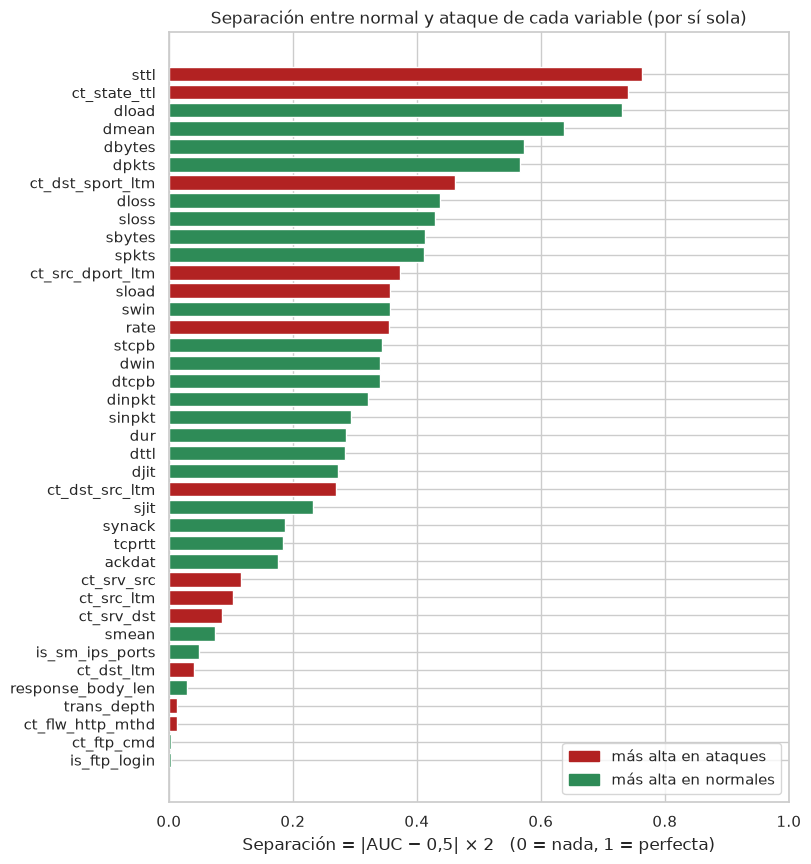

In [71]:
direction_colors = separation["más alta en"].map({"ataques": "firebrick", "normales": "seagreen"})
ordered = separation.iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(ordered.index, ordered["separación"], color=direction_colors.iloc[::-1])
ax.set_title("Separación entre normal y ataque de cada variable (por sí sola)")
ax.set_xlabel("Separación = |AUC − 0,5| × 2   (0 = nada, 1 = perfecta)")
ax.set_xlim(0, 1)
ax.legend(
    handles=[plt.Rectangle((0, 0), 1, 1, color="firebrick"), plt.Rectangle((0, 0), 1, 1, color="seagreen")],
    labels=["más alta en ataques", "más alta en normales"], loc="lower right",
)
plt.show()

Lo que más separa es TTL, y después la respuesta del destino. Las seis mejores sin TTL:

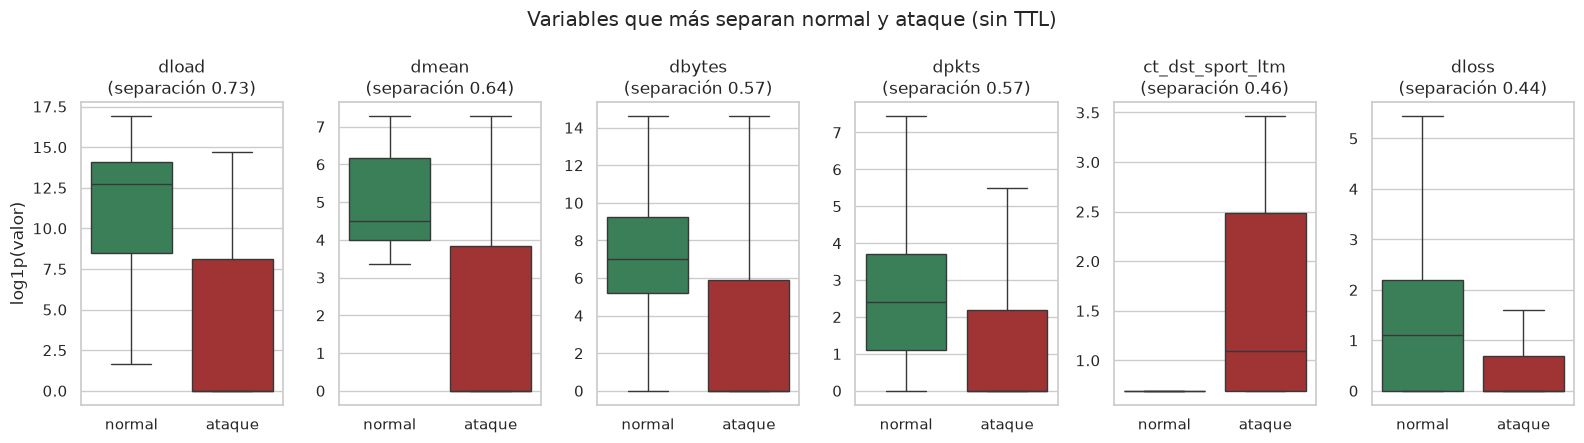

In [72]:
ttl_cols = ["sttl", "dttl", "ct_state_ttl"]
top_non_ttl = [c for c in separation.index if c not in ttl_cols][:6]

fig, axes = plt.subplots(1, len(top_non_ttl), figsize=(16, 4.5))
for ax, col in zip(axes, top_non_ttl):
    sns.boxplot(x=train[TARGET].map({0: "normal", 1: "ataque"}), y=np.log1p(train[col]),
                hue=train[TARGET].map({0: "normal", 1: "ataque"}),
                palette={"normal": "seagreen", "ataque": "firebrick"}, showfliers=False, legend=False, ax=ax)
    ax.set_title(f"{col}\n(separación {separation.loc[col, 'separación']:.2f})")
    ax.set_xlabel("")
    ax.set_ylabel("log1p(valor)" if col == top_non_ttl[0] else "")
fig.suptitle("Variables que más separan normal y ataque (sin TTL)")
fig.tight_layout()
plt.show()

La mitad o más de los ataques no reciben respuesta (su caja queda en 0), y repiten muchas más conexiones.

La separación sirve para las numéricas. Para `proto`, `service` y `state` usamos la **V de Cramér** frente a `label` (0 = sin relación, 1 = relación perfecta), con las categorías originales y con las agrupadas en `other`:

In [ ]:
def cramers_v(x, y):
    """V de Cramér entre dos variables categóricas: 0 = sin relación, 1 = relación perfecta."""
    observed = pd.crosstab(x, y)
    n = observed.to_numpy().sum()
    # Frecuencias esperadas si no hubiera relación: total de la fila × total de la columna / n.
    expected = np.outer(observed.sum(axis=1), observed.sum(axis=0)) / n
    chi2 = ((observed.to_numpy() - expected) ** 2 / expected).sum()
    return np.sqrt(chi2 / (n * (min(observed.shape) - 1)))


association = {}
for col in categorical_cols:
    kept = train_counts[col].index[train_counts[col] >= MIN_CATEGORY_COUNT]
    grouped = train[col].where(train[col].isin(kept), "other")  # agrupación de la decisión 8
    association[col] = {
        "categorías": train[col].nunique(),
        "V de Cramér": cramers_v(train[col], train[TARGET]),
        "categorías agrupadas": grouped.nunique(),
        "V de Cramér (agrupadas)": cramers_v(grouped, train[TARGET]),
    }

association = pd.DataFrame(association).T.astype({"categorías": int, "categorías agrupadas": int})
association.round(3).sort_values("V de Cramér", ascending=False)

- **`state` es la categórica más asociada con el ataque** (0,56), seguida de `proto` (0,43) y `service` (0,27).
- **Agrupar en `other` no pierde información:** `proto` pasa de 133 a 7 categorías y su V queda casi igual (0,435 → 0,434). Las categorías raras no aportaban; esto respalda la decisión 8.
- La V de Cramér y la separación miden cosas distintas, así que sus valores no se comparan entre sí.

## 8. Variables redundantes

Una variable que repite lo que ya dice otra no aporta nada y, en la app, se reparte la contribución con ella. Primero buscamos copias exactas:

In [ ]:
is_tcp = train["proto"] == "tcp"
tcp_with_handshake = is_tcp & (train["synack"] > 0)

print(f"is_ftp_login = ct_ftp_cmd: {(train['is_ftp_login'] == train['ct_ftp_cmd']).mean():.1%} de los flujos")
print(f"tcprtt = synack + ackdat:  {np.isclose(train['tcprtt'], train['synack'] + train['ackdat'], atol=1e-6).mean():.1%} de los flujos")
# Spearman solo donde tcprtt tiene sentido: TCP con conexión establecida.
tcprtt_synack = train.loc[tcp_with_handshake, ["tcprtt", "synack"]].corr(method="spearman").iloc[0, 1]
print(f"Correlación de Spearman tcprtt–synack: {tcprtt_synack:.2f}")

- `is_ftp_login` y `ct_ftp_cmd` son la misma columna en todo el entrenamiento.
- `tcprtt` es exactamente `synack + ackdat` y ordena los flujos casi igual que `synack` (0,97).

> **Decisión 4:** quitamos `is_ftp_login` y conservamos `ct_ftp_cmd`.
>
> **Decisión 12:** quitamos `tcprtt`; se conservan `synack` y `ackdat`.

Luego, variables que separan bien en general pero quizá solo porque dicen "es TCP". Medimos su separación en todos los flujos y solo dentro de TCP:

In [ ]:
tcp_flows = train[is_tcp]
tcp_only = ["stcpb", "dtcpb", "swin", "dwin"]

print(f"swin = 255 en el {(tcp_flows['swin'] == 255).mean():.2%} de los flujos TCP; fuera de TCP vale {train.loc[~is_tcp, 'swin'].unique().tolist()}")
dwin_zero = tcp_flows["dwin"] == 0
print(f"Flujos TCP con dwin = 0: {dwin_zero.sum()}, de ellos sin respuesta (dpkts = 0): {(dwin_zero & (tcp_flows['dpkts'] == 0)).sum()}")

pd.DataFrame({
    "separación (todos los flujos)": separation.loc[tcp_only, "separación"],
    "separación (solo TCP)": [
        round(abs(univariate_auc(tcp_flows[c], tcp_flows[TARGET]) - 0.5) * 2, 3) for c in tcp_only
    ],
})

- **`stcpb` y `dtcpb`** (números de secuencia TCP, aleatorios por diseño) y **`swin`** separan 0,34–0,36 en general, pero casi nada dentro de TCP: lo único que dicen es "es TCP".
- **`dwin`** vale 0 en los flujos TCP sin respuesta (857 de 858): dice "es TCP y el destino respondió".

> **Decisión 10:** quitamos `stcpb` y `dtcpb`.
>
> **Decisión 11:** quitamos `swin` y `dwin`; lo que dicen ya está en `proto` y `dpkts`.

Con las variables que quedan miramos las correlaciones entre pares. Usamos Spearman, que compara el orden de los valores (rojo = suben juntas, azul = una sube y la otra baja):

In [ ]:
dropped_so_far = ["is_ftp_login", "tcprtt", "stcpb", "dtcpb", "swin", "dwin"]  # decisiones 4, 10, 11 y 12
corr_cols = [c for c in numeric_cols if c not in dropped_so_far]
# Spearman compara el orden de los valores, así que las colas largas no la distorsionan.
spearman = train[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(spearman, mask=np.triu(np.ones_like(spearman, dtype=bool)), cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.3, cbar_kws={"shrink": 0.7, "label": "correlación de Spearman"}, ax=ax)
ax.set_title(f"Correlación de Spearman entre las {len(corr_cols)} variables numéricas restantes")
ax.grid(False)
plt.show()

Hay bloques rojos grandes. Para ver si son copias, recalculamos algunos de los pares más altos solo en los flujos donde las variables tienen sentido:

In [ ]:
upper = spearman.where(np.triu(np.ones_like(spearman, dtype=bool), k=1)).stack()
print(f"Pares con |correlación| >= 0,95: {(upper.abs() >= 0.95).sum()}")


def spearman_pair(a, b, rows):
    """Correlación de Spearman entre dos variables, solo en las filas indicadas."""
    return train.loc[rows, [a, b]].corr(method="spearman").iloc[0, 1]


pair_checks = [
    ("trans_depth", "ct_flw_http_mthd", train["trans_depth"] > 0, "con actividad HTTP"),
    ("dpkts", "dbytes", train["dpkts"] > 0, "con respuesta"),
    ("synack", "ackdat", tcp_with_handshake, "TCP con conexión establecida"),
]
pd.DataFrame([
    {"par": f"{a} – {b}",
     "todos los flujos": round(spearman.loc[a, b], 3),
     "solo donde tienen sentido": round(spearman_pair(a, b, rows), 3),
     "subconjunto": label}
    for a, b, rows, label in pair_checks
]).set_index("par")

- **Las correlaciones altas vienen de ceros compartidos:** fuera de TCP, sin respuesta del destino o sin HTTP, varias variables valen 0 a la vez. Al quitar esos ceros bajan: `trans_depth`–`ct_flw_http_mthd` pasa de 1,00 a −0,02.
- Las que siguen altas (`dpkts`–`dbytes`, 0,94) miden cosas distintas que suelen ir juntas; no son copias.
- `rate` (−0,97 con `dur`) se conserva: es una división de paquetes entre duración que los modelos no reconstruyen solos.

> **Decisión 13:** no quitamos más variables por correlación.

## 9. El atajo de TTL

El TTL depende del sistema operativo y de la red, no de si el flujo es un ataque. Aun así separa casi todo:

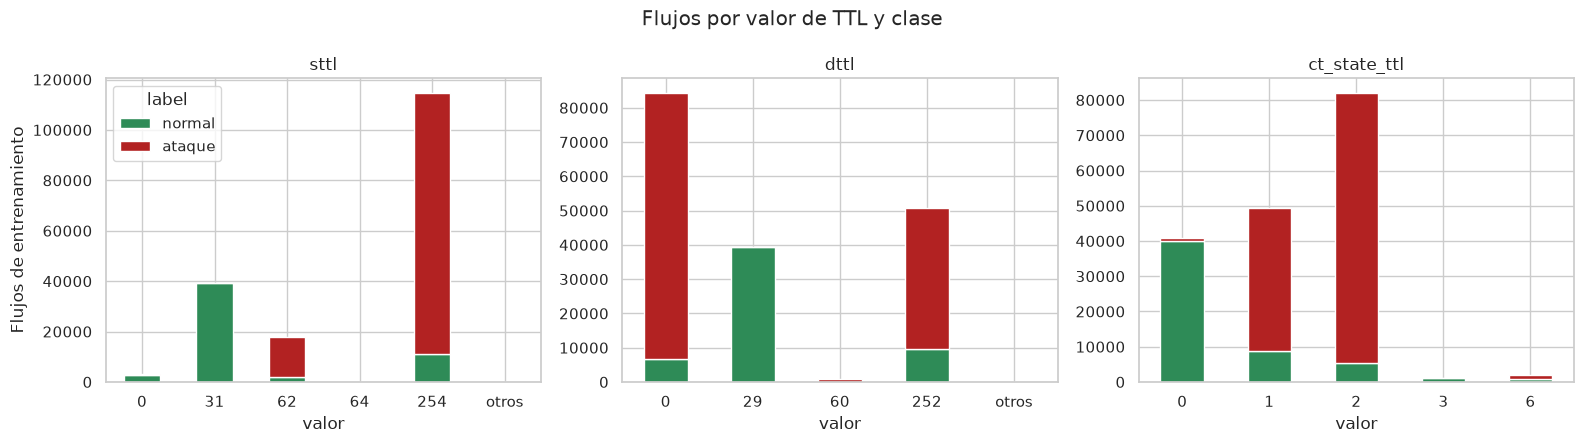

In [73]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ttl_cols):
    counts = train[col].value_counts()
    frequent = counts.index[counts >= 100]
    values = train[col].where(train[col].isin(frequent), other=-1)  # solo para visualizar
    table = pd.crosstab(values, train[TARGET]).rename(index={-1: "otros"}, columns={0: "normal", 1: "ataque"})
    table.index = table.index.astype(str)
    table = table.loc[[v for v in table.index if v != "otros"] + [v for v in table.index if v == "otros"]]
    table.plot.bar(stacked=True, color=["seagreen", "firebrick"], ax=ax, rot=0, legend=(col == ttl_cols[0]))
    ax.set_title(col)
    ax.set_xlabel("valor")
    ax.set_ylabel("Flujos de entrenamiento" if col == ttl_cols[0] else "")
fig.suptitle("Flujos por valor de TTL y clase")
fig.tight_layout()
plt.show()

`sttl = 31` son 39.455 flujos, todos normales: es un grupo de equipos del laboratorio. Comparamos la proporción de ataques por valor de `sttl` en entrenamiento y prueba:

In [74]:
sttl_comparison = pd.DataFrame({
    "flujos (entrenamiento)": train["sttl"].value_counts(),
    "% ataques (entrenamiento)": train.groupby("sttl")[TARGET].mean() * 100,
    "flujos (prueba)": test["sttl"].value_counts(),
    "% ataques (prueba)": test.groupby("sttl")[TARGET].mean() * 100,
}).loc[lambda d: d["flujos (entrenamiento)"] >= 1000].round(1)
sttl_comparison

,flujos (entrenamiento),% ataques (entrenamiento),flujos (prueba),% ataques (prueba)
sttl,,,,
0,3162.0,9.6,1048.0,5.8
31,39455.0,0.0,16702.0,0.0
62,17681.0,87.7,10374.0,60.2
254,114743.0,90.2,54049.0,72.2


Lo mismo en una gráfica:

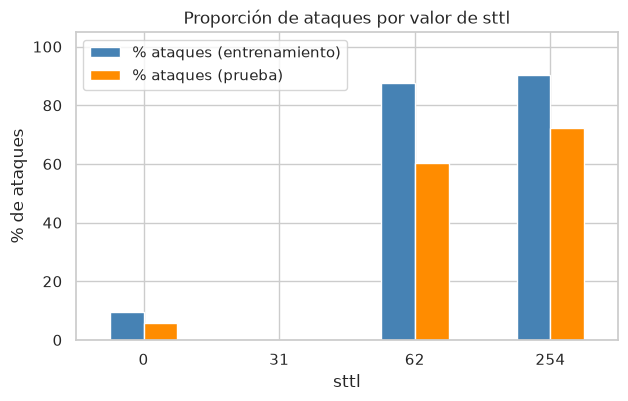

In [75]:
fig, ax = plt.subplots(figsize=(7, 4))
sttl_comparison[["% ataques (entrenamiento)", "% ataques (prueba)"]].plot.bar(ax=ax, color=["steelblue", "darkorange"], rot=0)
ax.set_title("Proporción de ataques por valor de sttl")
ax.set_xlabel("sttl")
ax.set_ylabel("% de ataques")
ax.set_ylim(0, 105)
plt.show()

En la prueba la pista se debilita (`sttl = 254` baja de 90 % a 72 % de ataques).

> **Decisión 14:** conservamos `sttl`, `dttl` y `ct_state_ttl`, marcadas como atajo conocido. Comparar modelos con y sin TTL lo decidimos en la etapa de entrenamiento.

## 10. Resumen de decisiones

| # | Qué decidimos | Por qué |
|---|---|---|
| 1 | Cuando el servicio de la conexión viene como "-" (servicio poco usado), lo tratamos como un valor más, igual que http o dns. | Dice algo: con "-" hay 61 % de ataques y con servicio conocido, 76 %. |
| 2 | No borramos los flujos repetidos. Al separar los datos para validar, todas las copias de un mismo flujo van juntas, o a entrenamiento o a validación. | Son conexiones distintas que se ven iguales porque los datos no traen IPs, puertos ni horas. Separarlas así evita validar con flujos que el modelo ya vio. |
| 3 | Dejamos los flujos idénticos que tienen etiquetas distintas (uno normal y otro ataque). | No hay forma de saber cuál etiqueta es la correcta; el modelo aprende la proporción real. |
| 4 | Quitamos la variable que marca si hubo inicio de sesión FTP (*is_ftp_login*). | En entrenamiento es idéntica al conteo de comandos FTP (*ct_ftp_cmd*), que se conserva. |
| 5 | Al separar entrenamiento y validación mantenemos la proporción de cada tipo de ataque. | Así hasta el tipo más escaso (Worms, 130 flujos) queda representado en la validación. |
| 6 | No quitamos ni recortamos los valores extremos (atípicos). | El 81 % de los flujos tiene alguno y no son errores: en varias variables casi todos los valores extremos son ataques. |
| 7 | A 21 variables con valores muy extremos (bytes, paquetes, tasas, tiempos) les aplicamos un logaritmo, log(1 + x). | Comprime las colas largas y deja ver diferencias entre normal y ataque. No cambia el orden de los valores. |
| 8 | En protocolo, servicio y estado, los valores con menos de 1.000 flujos se agrupan en "otros". También van a "otros" los valores nuevos o vacíos. | Con tan pocos ejemplos el modelo no aprende nada fiable de cada uno, y así nunca se rechaza un flujo por traer un valor desconocido. |
| 9 | Protocolo, servicio y estado se convierten en columnas de sí/no, una por cada valor (21 columnas), siempre las mismas y en el mismo orden. | Los modelos necesitan números, y una lista fija garantiza que la app prepare los datos igual que en el entrenamiento. |
| 10 | Quitamos los números de secuencia TCP de origen y destino (*stcpb*, *dtcpb*). | Son números aleatorios por diseño del protocolo; lo único que indican es si la conexión es TCP, y eso ya lo dice el protocolo. |
| 11 | Quitamos los tamaños de ventana TCP de origen y destino (*swin*, *dwin*). | Solo indican si la conexión es TCP y si hubo respuesta, algo que ya dicen el protocolo y los paquetes de respuesta. |
| 12 | Quitamos el tiempo total del saludo inicial TCP (*tcprtt*). | Es la suma exacta de sus dos partes (*synack* y *ackdat*), que se conservan. |
| 13 | No quitamos más variables por estar muy correlacionadas entre sí. | La correlación alta viene de que muchas valen 0 a la vez (tráfico no TCP, sin respuesta, no web) y desaparece donde las variables sí aplican. |
| 14 | Conservamos las variables de tiempo de vida de los paquetes, TTL (*sttl*, *dttl*, *ct_state_ttl*), marcadas como atajo conocido. | En este dataset delatan casi solas si es ataque (un solo corte en *sttl* acierta el 92 %), por cómo se armó el laboratorio. Se marcan para poder entrenar también sin ellas y comparar. |
| 15 | Quitamos la marca "misma IP y puerto en origen y destino" (*is_sm_ips_ports*). | Casi todos sus casos son tráfico ARP, lo mismo que ya dice el protocolo. |
| 16 | Si un flujo trae un valor numérico vacío, no numérico o negativo, se rechaza con un mensaje claro. | No inventamos valores que no conocemos. |

**Resultado:** las 42 variables originales (sin contar el identificador ni las etiquetas) quedan en **53 columnas de entrada para el modelo**: 32 numéricas y 21 de sí/no para protocolo, servicio y estado. Sin las variables de TTL quedan 50.

**Pendiente para la etapa de entrenamiento:** escalado, manejo del desbalance, métricas por clase, modelos con y sin TTL, y cómo reportar la prueba y las falsas alarmas.